# Libraries

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from shapely.geometry import LineString, Point, MultiPoint, Polygon
import copy as copy
import seaborn as sns
import json
import os
import itertools
import scipy
from sklearn.preprocessing import QuantileTransformer
# np.random.seed(42)

# Process original forecast error data
- The source of the forecast error data: https://www.nhc.noaa.gov/verification/verify7.shtml
- For the description of the column names, check https://www.nhc.noaa.gov/verification/pdfs/Error_Tabulation_File_Format.pdf or *data/Error_Tabulation_File_Format.pdf*.
- The missing data is marked as **-9999.0**
- The data for 60h, 84h, and 108h are missing.
    - To represent these hours, we average the data before and after.

In [2]:
data_dir = 'mc_data/'
output_dir = 'mc_output/'
os.makedirs(output_dir, exist_ok=True)

## Input Arguments

In [3]:
with open('mc_data/inputs.json') as f:
    raw = json.load(f)
args = {
    k: (v['value'] if isinstance(v, dict) and 'value' in v else v)
    for k, v in raw.items()
}
pd.DataFrame.from_dict(
    args, orient='index', columns=['val']
    ).rename_axis('arg')

,val
arg,
T_original,11
start_year,1970
LONG_TO_MILES,54.6
LAT_TO_MILES,69.0
CRS,EPSG:4326
H,120
demand_lead_time,48
segments,1
n_states_at_terminal,5


## Parameters and auxiliary variables

In [4]:
# Excluded 84h and 108h
hours = [str(12 * i) for i in range(args['T_original']) if i not in [7, 9]]
# save as strings with leading zeros
hours = list(map(lambda h: '0' + h if len(h) == 2 else h, hours))
hours[0] = '000'
# The types of forecast errors
err_types = ['along', 'cross', 'track', 'intensity']
# Error groups: AC (along/cross), TI (track/intensity)
err_grp = ['AC', 'TI']
# The column names in NHC forecast error files:
error_columns = dict(
    AC={'along': list(map(lambda h: h + "hA01", hours)),
        'cross': list(map(lambda h: h + "hC01", hours))},
    TI={'track': list(map(lambda h: h + "hT01", hours)),
        'intensity': list(map(lambda h: h + "hI01", hours))}
    )
# The total number of planning periods in the original horizon to consider.
T = int(args['H'] / 12) + 1
planning_horizon_extended = range((T - 1) * args['segments'] + 1)
T_exteneded = len(planning_horizon_extended)
# np.random.seed(42)

## Read Data

In [5]:
'''forecast error data'''
raw_data = {}
for err in err_grp:
    raw_data[err] = pd.read_csv(
        data_dir + f'1970-present_OFCL_v_BCD5_ind_ATL_{err}_errors_noTDs.txt',
        skiprows=10,
        header=0,
        sep=r'\s+',
        )

In [6]:
'''Load the point forecast and study region data'''
x_rotate = args['X_rotate']  # to rotate axis along study region
y_rotate = args['Y_rotate']  # to rotate axis along study region
# SC map and study regions as GeoDataFrame
geoms = gpd.read_file("mc_data/geoms.geojson")
geoms.crs = args['CRS']
# forecast time stamp
with open('mc_data/forecast_time_stamps.json', 'r') as f:
    forecast_time_stamps = json.load(f)
forecast_time_stamp = forecast_time_stamps[str(args['H'])]
# NHC point forecast data
forecast_original = pd.read_csv('mc_data/Florence_forecast.csv', index_col=0)
fore_original_pos = forecast_original[['Longitude', 'Latitude']].values
forecast_gdf = gpd.GeoDataFrame({
    'object': ['forecast'],
    'geometry': [LineString(fore_original_pos)]
    }, crs=args['CRS'])
forecast_original

,Longitude,Latitude,Intensity
T,,,
0,-55.50,24.50,60.0
1,-56.70,24.60,70.0
2,-58.30,24.80,85.0
3,-60.40,25.30,100.0
4,-63.10,26.10,110.0
5,-66.10,27.15,117.5
6,-69.10,28.20,125.0
7,-71.95,29.75,122.5
8,-74.80,31.30,120.0


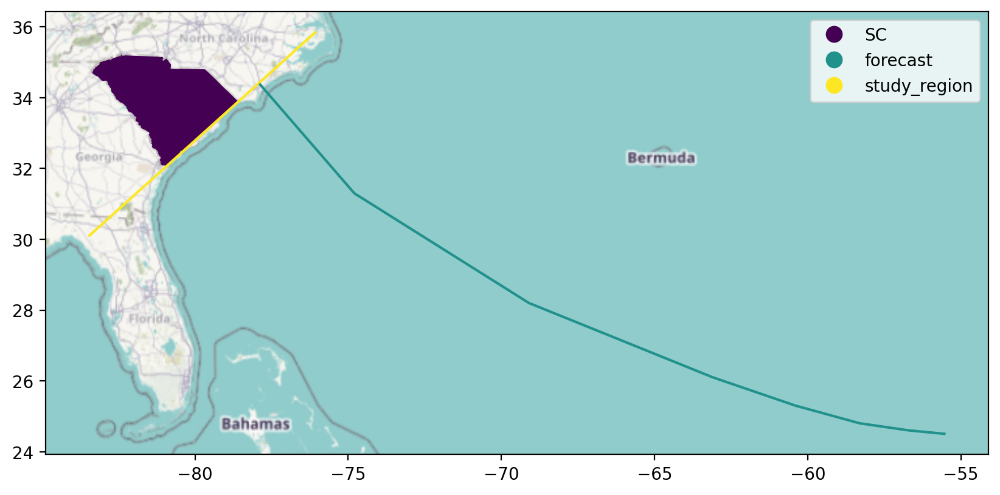

In [7]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
pd.concat([geoms, forecast_gdf]).plot(
    ax=ax, legend=True, column='object', cmap='viridis'
    )
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)

## Initial wrangling

In [9]:
def split_dataframes(data):
    df_unprocessed_temp = copy.deepcopy(data)
    dfs_new = {}
    for i, df_split in df_unprocessed_temp.items():
        df_split[['Date', 'Time']] = df_split["Date/Time"].str.split("/", expand=True)
        df_split[['Day', 'Month', 'Year']] = df_split['Date'].str.split('-', expand=True).astype('int')
        df_split["Date/Time"] = pd.to_datetime(df_split["Date/Time"], format="%d-%m-%Y/%H:%M:%S")
        df_split.set_index(['STMID', 'Date/Time', 'Lat', 'Lon'], inplace=True)
        df_split = df_split.loc[df_split["Year"] >= args['start_year']]
        for error_name, cols in error_columns[i].items():
            df_single_error = df_split[cols]
            df_single_error = df_single_error.where(df_single_error != -9999.0, None)
            df_single_error = df_single_error.dropna(how='all')
            df_single_error.drop(error_columns[i][error_name][0], axis=1, inplace=True)
            df_single_error.drop(error_columns[i][error_name][5], axis=1, inplace=True)
            df_single_error.insert(0, error_columns[i][error_name][0], 0)
            df_single_error = df_single_error.loc[~(df_single_error == 0.0).all(axis=1)]

            # Insert missing columns to maintain 12 hours differences
            cols = df_single_error.columns
            error_group = list(cols[0])[-3]
            for h in [60, 84, 108]:
                prev_hour = str(h - 12).zfill(3)
                next_hour = str(h + 12).zfill(3)
                error = (df_single_error[prev_hour + "h" + error_group + "01"] +
                       df_single_error[next_hour + "h" + error_group + "01"]
                      ) / 2
                col_position = df_single_error.columns.get_loc(prev_hour + "h" + error_group + "01") + 1
                df_single_error.insert(col_position, f"{h}h{error_group}01", error)
            dfs_new[error_name] = df_single_error
    return dfs_new

dt_fe_split = split_dataframes(raw_data)

In [13]:
def process_fe_data(dt_fe_splitted, nan_opt=1):
    """
    nan_opt = 1 if all rows with at least one Nan entry are deleted;
    nan_opt = 2 if a time series data fill rows with Nan entry.
    """
    df_unprocessed_temp = copy.deepcopy(dt_fe_splitted)
    dfs_new = {}
    for err, df in df_unprocessed_temp.items():
        df_temp = df[df.columns[:T]]
        if nan_opt == 1:
            df_temp = df_temp.dropna(how='any')
        else:
            df_temp = df_temp.dropna(how='all')  # all nan
            df_temp = df_temp.dropna(subset=[df_temp.columns[1]])  # 12h
            df_temp = df_temp.dropna(thresh=7)
            df_temp = df_temp.bfill()
            df_temp = df_temp.ffill()
        df_temp = df_temp.round(0)
        dfs_new[err] = df_temp
    common_indices = dfs_new['intensity'].index
    for key, df in dfs_new.items():
        if key == 'intensity':
            continue
        common_indices = common_indices.intersection(df.index)
    common_dfs = {key: df.loc[common_indices] for key, df in dfs_new.items()}
    return common_dfs

processed_data = process_fe_data(dt_fe_split, nan_opt=1)
track_error = processed_data['cross']
intensity_error = processed_data['intensity']

# AR(1) Model: data-driven AR(1) models of the forecast error
**Steps**
- Transform the forecast errors $$X^{\text{TRANSFORMED}} = \text{QuantileTransformer(X)}$$
- Fit an AR(1) model
- Simulate the AR(1) forecast error samples
- Restore the transformation: $$ X = \text{QuantileTransformer.inverse\_transform}(X^{\text{TRANSFORMED}})$$

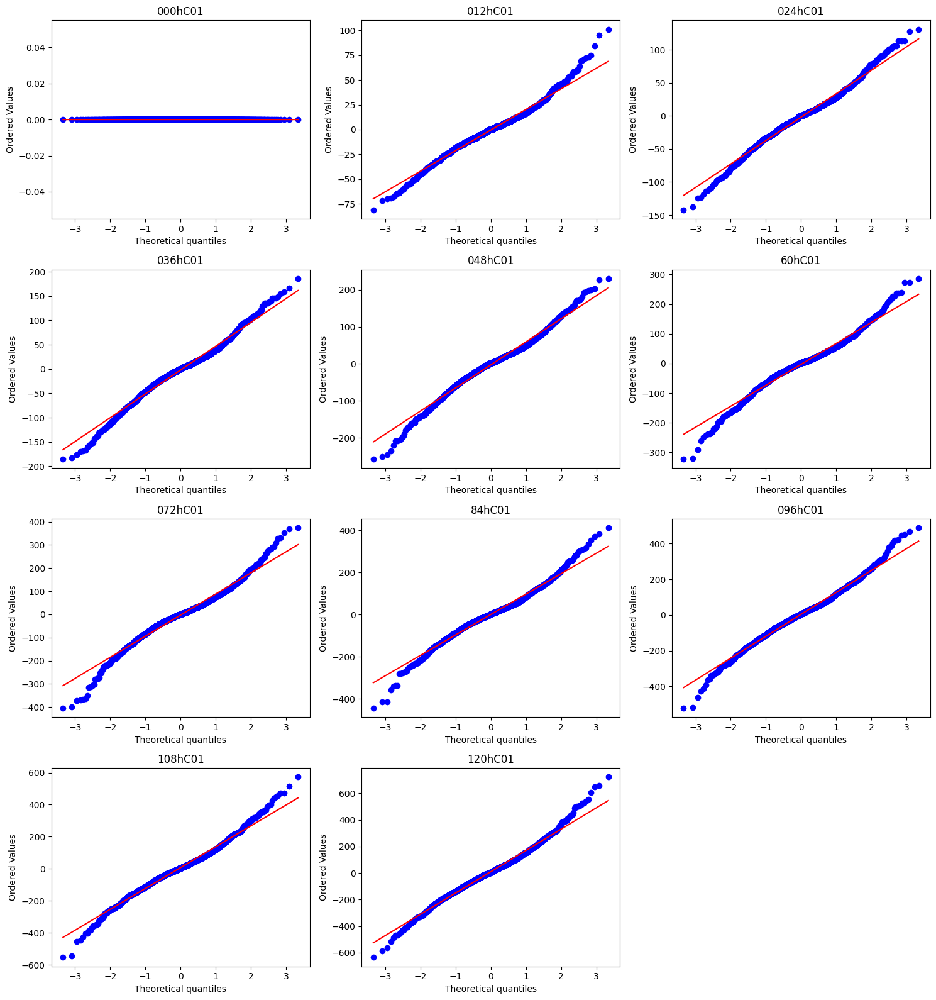

In [17]:
def qq_plots_grid(df):
    cols = df.columns
    n = len(cols)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        scipy.stats.probplot(df[col].dropna(), dist="norm", plot=ax)
        ax.set_title(col)

    # Remove unused subplots
    for ax in axes[len(cols):]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

qq_plots_grid(track_error)


## Transformation to address heavy tails

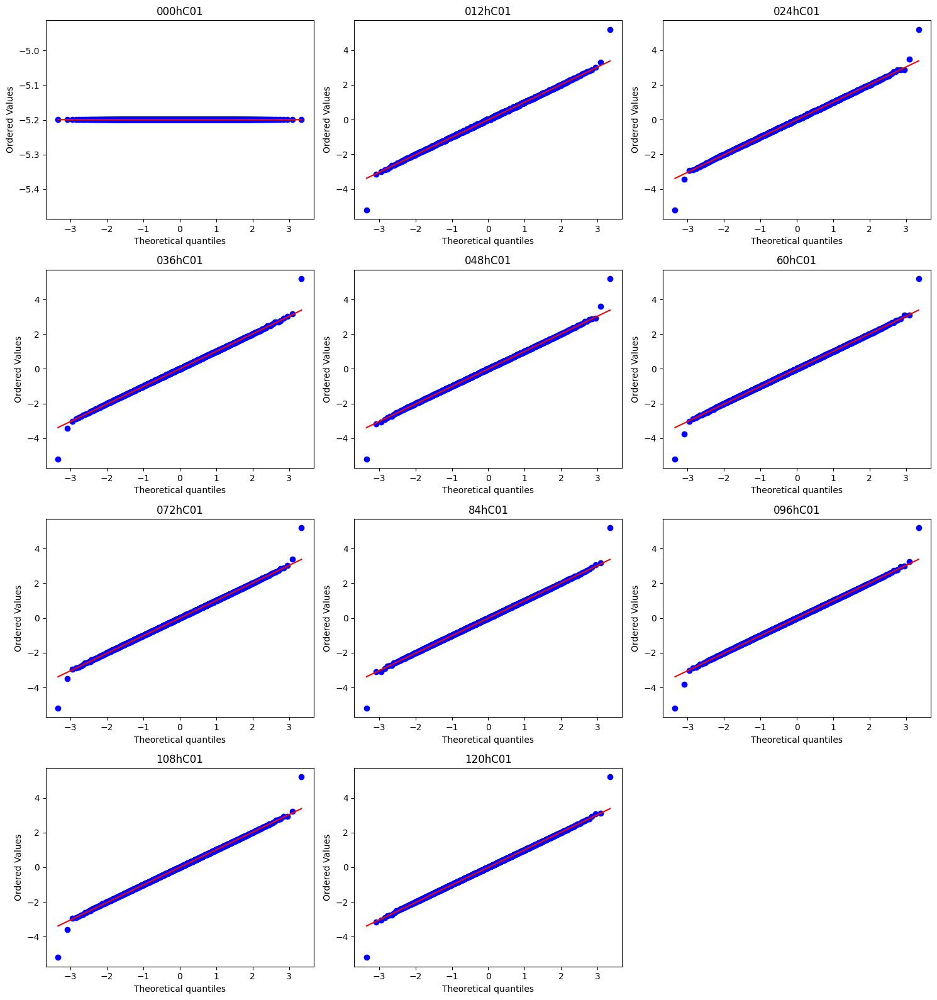

In [18]:
qt = QuantileTransformer(output_distribution='normal', random_state=42)
track_error_transformed = qt.fit_transform(track_error)
track_error_transformed = pd.DataFrame(
    data=track_error_transformed,
    columns=track_error.columns
    )
qq_plots_grid(track_error_transformed)

## MLE to achieve AR(1) parameters

In [19]:
def ar1_params_mle(historical_data):
    n_training_samples, n_periods = historical_data.shape
    rho = sum(sum(
        historical_data[i, t] * historical_data[i, t-1]
        for t in range(1, n_periods)) for i in range(n_training_samples)
        ) / sum(sum(
            historical_data[i, t - 1] ** 2
            for t in range(1, n_periods)) for i in range(n_training_samples))
    sigma = np.sqrt(
        1.0/(n_training_samples * (n_periods - 1)) * sum(sum(
            (historical_data[i, t] - rho * historical_data[i, t-1])**2
            for t in range(1, n_periods)) for i in range(n_training_samples))
        )
    return rho, sigma

rho_track, sigma_track = ar1_params_mle(track_error_transformed.values)
rho_intensity, sigma_intensity = ar1_params_mle(intensity_error.values)

print(
    'track: rho[{:.2f}] sigma[{:.2f}]'.format(rho_track, sigma_track),
    'intensity: rho[{:.2f}] sigma[{:.2f}]'.format(rho_intensity, sigma_intensity),
    sep='\n'
    )

track: rho[0.22] sigma[0.92]
intensity: rho[0.95] sigma[8.81]


## Simulate AR(1) samples of the forecast error
- For samples $i = 1, \ldots, M$:
$$\xi^i_t = \rho^{\text{MLE}} \xi^i_{t - 1} + \epsilon_t; \quad \epsilon_t \sim \mathbb{N}(0, \sigma^{\text{MLE}^2}) $$

### Construct a recombined tree for $\epsilon_t$

In [20]:
samples_shape = (args['num_scen'], T)
eps_tree_track = np.random.normal(0, sigma_track, samples_shape)
eps_tree_intensity = np.random.normal(0, sigma_intensity, samples_shape)

### Simulate AR(1) samples

In [23]:
def simulate_ar1(rho, eps_tree):
    samples = np.zeros(samples_shape)
    for t in range(1, T):
        eps_vec = eps_tree[:, t].copy()
        np.random.shuffle(eps_vec)
        samples[:, t] = rho * samples[:, t - 1] + eps_vec
    return samples

samples_track_transformed = simulate_ar1(rho_track, eps_tree_track)
samples_intensity = simulate_ar1(rho_intensity, eps_tree_intensity)

### Revert the transformation of track error

<Axes: >

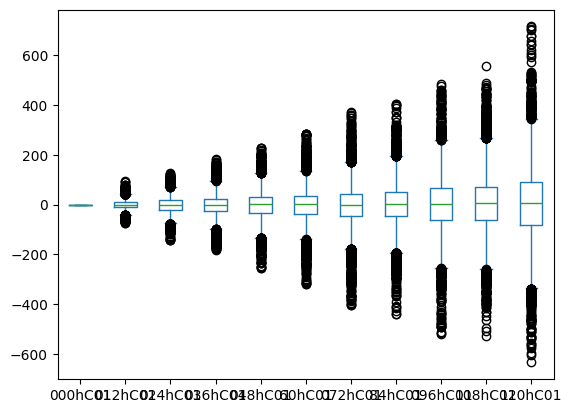

In [24]:
samples_track_transformed_df = pd.DataFrame(
    data=samples_track_transformed,
    columns=track_error.columns,
    )
samples_track = qt.inverse_transform(samples_track_transformed_df)
pd.DataFrame(samples_track,columns=track_error.columns).plot.box()

### If using true samples instead of AR(1) samples

In [25]:
if args['ar_1_sample'] == 0:
    samples_track = processed_data['cross']
    samples_intensity = processed_data['intensity']
else:
    pass

# Helper functions

In [26]:
def points_from_ls(linestring: LineString):
    '''
    Given a shapely LineString, return list of shapely Points for
    each vertex in the LineString. Useful in plotting the points along
    a LineString in geopandas.
    '''
    return [Point(x, y) for geom in linestring for x, y in geom.coords]

In [27]:
def divide_linestring(linestring: LineString, segments: int):
    """
    Return list of shapely Points at the segment boundaries.
    segments: number of equal segments
        (returns segments+1 points including endpoints)
    """
    assert segments > 0, 'segments must be > 0'
    L = linestring.length
    pts = [linestring.interpolate(L * i/segments) for i in range(segments+1)]
    return pts

In [28]:
def track_pos_from_cross_err(fore: pd.DataFrame, fore_error: list):
    x_coord = list(
        x + x_rotate * e / args['LONG_TO_MILES']
        for x, e in zip(fore['Longitude'], fore_error)
        )
    y_coord = list(
        y + y_rotate * e/args['LAT_TO_MILES']
        for y, e in zip(fore['Latitude'], fore_error)
        )
    return x_coord, y_coord

In [29]:
def point_of_intersection(line1: LineString, line2: LineString):
    '''
    Given two shapely LineStrings, return the (x, y) coordinates of their
    point of intersection. Assumes that the two lines intersect at exactly
    one point.
    '''
    assert line1.intersects(line2), "Lines do not intersect"
    inter = line1.intersection(line2)
    assert not inter.is_empty, "Intersection is empty"
    if isinstance(inter, Point):
        pt = inter
    elif isinstance(inter, MultiPoint):
        if len(inter.geoms) != 1:
            raise AssertionError(
                f"Expected single point, got {len(inter.geoms)}"
                )
        pt = list(inter.geoms)[0]
    else:
        raise AssertionError(
            f"Intersection is not a single point: {inter.geom_type}"
            )
    return pt.x, pt.y

In [30]:
def polygon_from_two_lines(line1: LineString, line2: LineString) -> Polygon:
    """
    Build a simple polygon whose boundary follows line1 then the reversed line2.
    Remove consecutive duplicate vertices and ensure closed ring. Try to fix invalid
    geometries with buffer(0).
    """
    c1 = list(line1.coords)
    c2 = list(line2.coords)
    seq = c1 + c2[::-1]
    cleaned = [seq[0]]
    for p in seq[1:]:
        if p != cleaned[-1]:
            cleaned.append(p)
    if cleaned[0] != cleaned[-1]:
        cleaned.append(cleaned[0])
    poly = Polygon(cleaned)
    if not poly.is_valid:
        poly = poly.buffer(0)
    return poly

In [31]:
def hurr_cat(wind_speed):
    '''
    Given wind speed in miles per hour, return the Saffir-Simpson category.
    SS-Scale: https://www.nhc.noaa.gov/aboutsshws.php
    '''
    if wind_speed < 74:
        return 0
    elif 74 <= wind_speed <= 95:
        return 1
    elif 96 <= wind_speed <= 110:
        return 2
    elif 111 <= wind_speed <= 129:
        return 3
    elif 130 <= wind_speed <= 156:
        return 4
    else:
        return 5

In [32]:
def extend_straight_line(line, M):
    '''
    given shapely LineString and distance M,
    extend the line by M units in both directions
    '''
    (x0, y0), (x1, y1) = line.coords[0], line.coords[-1]
    dx, dy = x1 - x0, y1 - y0
    L = (dx**2 + dy**2)**0.5
    ux, uy = dx / L, dy / L
    new_start = (x0 - M * ux, y0 - M * uy)
    new_end   = (x1 + M * ux, y1 + M * uy)
    return LineString([new_start, new_end])

# Florence Forecast Data

- Retrieve archived forecast data from the A-Deck repository: https://ftp.nhc.noaa.gov/atcf/aid_public/
- Preprocess the data:
  - Clean the raw records
  - Remove unnecessary and redundant columns
  - Add forecast lead-time columns (60 h, 84 h, and 108 h) to enforce a consistent 12-hour interval structure
- Select forecasts based on predefined start times for each planning horizon using  
  `data/forecast_time_stamps.json`. This file maps each planning horizon (in hours) to the timestamp at which the forecast was issued, such that the predicted landfall occurs at the end of the planning horizon duration. For example, for a 60-hour planning horizon, the forecast issued at `2018-09-12 12:00:00` is predicted to make landfall 60 hours later.
- Project the final point of each forecast track onto the study line. This projected point serves as an approximation of the landfall location, ensuring consistency with demand points (DPs), which are also represented by their projections onto the study line.

## Read the data

In [36]:
df_forecast = pd.read_csv(
    data_dir + "aal062018.dat",
    sep=",",
    engine="python",
    header=None,
    skipinitialspace=True,
    usecols=range(9)
)
df_forecast = df_forecast[df_forecast[4]=='OFCL']
df_forecast = df_forecast.drop(columns=[0, 1, 3, 4])
df_forecast.reset_index(drop=True, inplace=True)
df_forecast.columns = ['datetime', 'hour', 'lat', 'long', 'wind_speed']
df_forecast['datetime'] = pd.to_datetime(
    df_forecast['datetime'],
    format='%Y%m%d%H'
    )
# Remove duplicate rows (all columns)
df_forecast = df_forecast.drop_duplicates()
# Keep only rows where hour is a multiple of 12
df_forecast = df_forecast[
    (df_forecast['hour'] % 12 == 0) & (df_forecast['hour'] <= 120)
    ]
df_forecast.head()

,datetime,hour,lat,long,wind_speed
0,2018-08-30 12:00:00,0,128N,179W,25
2,2018-08-30 12:00:00,12,132N,201W,30
3,2018-08-30 12:00:00,24,135N,220W,35
4,2018-08-30 12:00:00,36,140N,240W,45
5,2018-08-30 12:00:00,48,150N,270W,55


## Pre-processing

In [37]:
def convert_latlon(series):
    s = series.astype(str)
    value = s.str[:-1].astype(float) / 10
    direction = s.str[-1]
    sign = np.where(direction.isin(["S", "W"]), -1, 1)
    return value * sign

df_forecast['lat'] = convert_latlon(df_forecast['lat'])
df_forecast['long'] = convert_latlon(df_forecast['long'])
df_forecast.dropna(inplace=True)
df_forecast.head()

,datetime,hour,lat,long,wind_speed
0,2018-08-30 12:00:00,0,12.8,-17.9,25
2,2018-08-30 12:00:00,12,13.2,-20.1,30
3,2018-08-30 12:00:00,24,13.5,-22.0,35
4,2018-08-30 12:00:00,36,14.0,-24.0,45
5,2018-08-30 12:00:00,48,15.0,-27.0,55


## Remove unnecessary forecasts
- Florence made landfall on 09/14/2018 at around 6 AM.
- We do not need forecasts after 09/14/2018 6 AM onwards and before 09/8/2018 6 AM

In [40]:
start = "2018-09-07 00:06:00"
end = "2018-09-15 00:00:00"

df_forecast_flattened = pd.DataFrame()
df_forecast_flattened = df_forecast.pivot_table(
    index="datetime",
    columns="hour",
    values=["lat", "long", "wind_speed"],
    aggfunc="first"
    ).loc[start: end]
df_forecast_flattened.head()

lat                                            long  \
hour                  0     12    24    36    48    72    96    120   0     
datetime                                                                    
2018-09-07 06:00:00  25.1  25.1  25.0  25.0  25.1  26.2  27.5  30.0 -50.4   
2018-09-07 12:00:00  25.0  24.9  24.9  24.9  25.1  25.9  27.5  30.0 -51.4   
2018-09-07 18:00:00  24.8  24.6  24.6  24.6  24.8  25.8  27.5  30.5 -52.2   
2018-09-08 00:00:00  24.8  24.7  24.7  24.7  25.0  25.8  27.5  30.5 -52.8   
2018-09-08 06:00:00  24.6  24.6  24.6  24.6  24.9  26.0  28.0  30.9 -53.8   

                           ...             wind_speed                          \
hour                  12   ...   96    120        0     12    24    36    48    
datetime                   ...                                                  
2018-09-07 06:00:00 -51.8  ... -63.5 -70.0       55.0  55.0  55.0  60.0  70.0   
2018-09-07 12:00:00 -52.8  ... -65.5 -72.0       55.0  55.0  55.0  60.0  65.0   
2018-09-07 18:00:00 -53.5  ... -67.0 -73.0       55.0  55.0  55.0  60.0  70.0   
2018-09-08 00:00:00 -54.1  ... -68.5 -74.5       50.0  50.0  55.0  60.0  70.0   
2018-09-08 06:00:00 -55.0  ... -70.2 -75.8       55.0  60.0  65.0  75.0  90.0   

                                          
hour                   72     96     120  
datetime                                  
2018-09-07 06:00:00   95.0  110.0  110.0  
2018-09-07 12:00:00   90.0  110.0  115.0  
2018-09-07 18:00:00   90.0  110.0  115.0  
2018-09-08 00:00:00   95.0  115.0  115.0  
2018-09-08 06:00:00  105.0  120.0  125.0  

[5 rows x 24 columns]

## Splitting of combined data into track(x, y) and intensity

In [41]:
df_lat = df_forecast_flattened["lat"].copy()
df_long = df_forecast_flattened["long"].copy()
df_wind_speed = df_forecast_flattened["wind_speed"].copy()

best_track_florence = np.column_stack((
    df_long[0].values.flatten(),
    df_lat[0].values.flatten(),
))

gdf_best_track_florence = gpd.GeoDataFrame({
    'object': ['best_track'], 'geometry': [LineString(best_track_florence)]
    }, crs=args['CRS'])

def fill_missing_lead_times(df, step=12, max_hour=120):
    df = df.copy()
    df.columns = df.columns.astype(int)
    full_hours = np.arange(0, max_hour + step, step)
    df = (
        df
        .reindex(columns=full_hours)
        .interpolate(axis=1)
        .sort_index(axis=1)
    )
    return df

df_lat = fill_missing_lead_times(df_lat)
df_long = fill_missing_lead_times(df_long)
df_wind_speed = fill_missing_lead_times(df_wind_speed)

## Plot and animate forecasts at different lead times

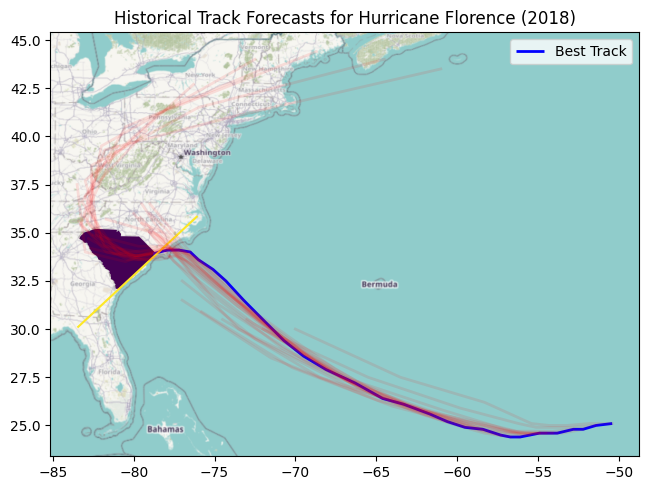

In [42]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
gdf_best_track_florence.plot(ax=ax, color='blue', linewidth=2, label='Best Track')
geoms.plot(
    ax=ax, legend=True, column='object', cmap='viridis'
    )
for time_step in df_forecast_flattened.index:
    fore_long = df_long.loc[time_step].values
    fore_lat = df_lat.loc[time_step].values
    ax.plot(
        fore_long, fore_lat, color='red', alpha=0.1, linewidth=2,
        # label='Forecast' if time_step == df_forecast_flattened['datetime'].unique()[0]
        # else ""
        )
ctx.add_basemap(ax, crs=args['CRS'], attribution=False)
ax.set_title('Historical Track Forecasts for Hurricane Florence (2018)')
ax.legend()
plt.tight_layout()

MovieWriter ffmpeg unavailable; using Pillow instead.


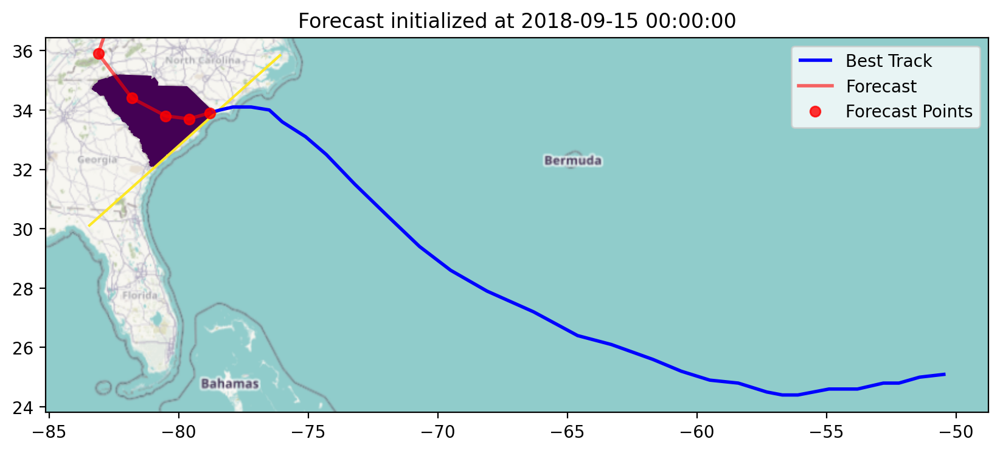

In [43]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
geoms.plot(
    ax=ax, legend=True, column='object', cmap='viridis'
    )
gdf_best_track_florence.plot(
    ax=ax, color='blue', linewidth=2, label='Best Track'
)
forecast_line, = ax.plot(
    [], [], color='red', alpha=0.6, linewidth=2, label='Forecast'
)

forecast_points, = ax.plot(
    [], [], linestyle='None', marker='o',
    color='red', alpha=0.8, markersize=6,
    label='Forecast Points'
)
ctx.add_basemap(ax, crs=args['CRS'], attribution=False)
ax.set_title('Historical Track Forecasts for Hurricane Florence (2018)')
ax.legend()

def update(time_step):
    fore_long = df_long.loc[time_step].values
    fore_lat  = df_lat.loc[time_step].values

    forecast_line.set_data(fore_long, fore_lat)
    forecast_points.set_data(fore_long, fore_lat)

    ax.set_title(f"Forecast initialized at {time_step}")
    return forecast_line, forecast_points

ani = FuncAnimation(
    fig,
    update,
    frames=df_forecast_flattened.index,
    interval=300,
    blit=True
)
ani.save(
    output_dir + 'florence_historical_forecasts.gif',
    writer="ffmpeg",
    fps=3,
    dpi=200
)

In [44]:
HTML(ani.to_jshtml())

## Selecting the desired forecast

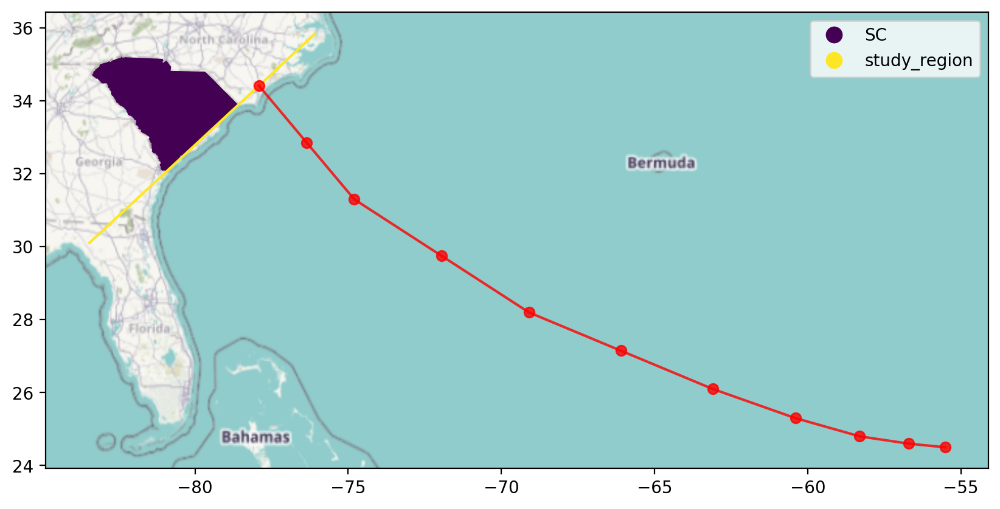

In [45]:
forecast = pd.DataFrame.from_dict({
    'Longitude': df_long.loc[pd.Timestamp(forecast_time_stamp)].values[:T],
    'Latitude': df_lat.loc[pd.Timestamp(forecast_time_stamp)].values[:T],
    'Intensity': df_wind_speed.loc[pd.Timestamp(forecast_time_stamp)].values[:T],
    })

'''Project the last forecast point to be within the study region'''
study_line = geoms.loc[geoms['object']=='study_region', 'geometry'].values[0]
last_point = Point(
    forecast['Longitude'].iloc[-1],
    forecast['Latitude'].iloc[-1]
    )
closest_point = study_line.interpolate(study_line.project(last_point))
forecast.loc[forecast.index[-1], 'Longitude'] = closest_point.x
forecast.loc[forecast.index[-1], 'Latitude']  = closest_point.y

fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
geoms.plot(ax=ax, legend=True, column='object', cmap='viridis')
ax.plot(
    forecast['Longitude'], forecast['Latitude'],
    color='red', alpha=0.8, markersize=6, marker='o',
    label='Forecast Points'
    )
ctx.add_basemap(ax, crs=args['CRS'], attribution=False)

# Create initial scenarios
- The historical forecast errors with 12 hours-long periods for the planning horizon.

In [ ]:
scen = np.zeros((args['num_scen'], T, 2))  # (num_scen, T, (long, lat))
for s in range(args['num_scen']):
    x_coord, y_coord = track_pos_from_cross_err(forecast, samples_track[s])
    scen[s] = np.column_stack((x_coord, y_coord))

lines = [LineString(scen[i]) for i in range(scen.shape[0])]
gdf_scen = gpd.GeoDataFrame({'geometry': lines})
gdf_scen.crs = args['CRS']

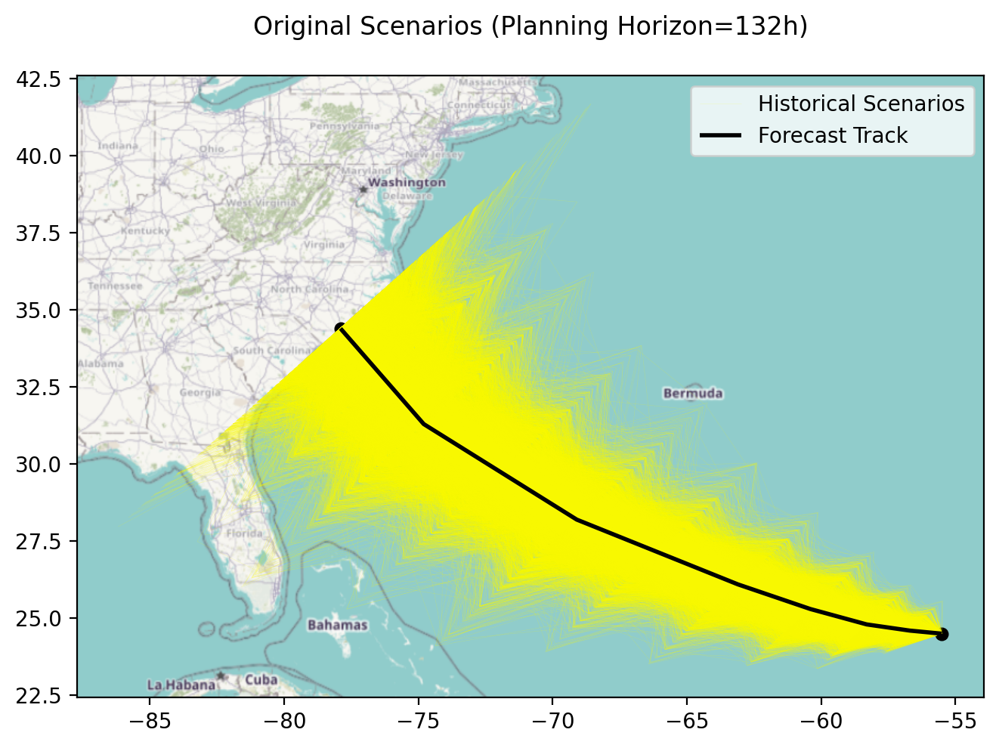

In [47]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
gdf_scen.plot(
    ax=ax, color='yellow', alpha=0.2, linewidth=0.2,
    label='Historical Scenarios'
    )
forecast_gdf.plot(
    ax=ax, color='black', linewidth=2, marker='x',
    label='Forecast Track'
    )
gpd.GeoSeries(
    points_from_ls(forecast_gdf.geometry),
    crs=forecast_gdf.crs
    ).plot(ax=ax, color='black', marker='o', markersize=30)
# add basemap using contextily
# NOTE: larger value for zoom takes longer time to load basemap
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)
ax.legend()
fig.suptitle(f'Original Scenarios (Planning Horizon={T*12}h)')
plt.tight_layout()

# Segmentation: split the forecast & scenarios into segments
- The original forecast has 12-hours periods starting at 120 hours before the landfall.
- In the folllowing, we divide the 12 hours period into short periods.
- Input 'H' conrols the desired planning horizon (number of hours before landfall).
- Input 'segments' controls the number of segments 12 hours period to split into.

## Data for the selected forecast horizon

In [48]:
'''Track scenarios for the truncated forecast horizon'''
scen_truncated = np.zeros((args['num_scen'], T, 2))  # (num_scen, T, (long, lat))
for s in range(args['num_scen']):
    x_coord, y_coord = track_pos_from_cross_err(forecast, samples_track[s])
    scen_truncated[s] = np.column_stack((x_coord, y_coord))
lines = [LineString(scen_truncated[i]) for i in range(scen_truncated.shape[0])]
gdf_scen_truncated = gpd.GeoDataFrame({'geometry': lines})
gdf_scen_truncated.crs = args['CRS']

## Extend the point forecast 

In [49]:
'''Create points in between subsequest forecast points at 12 hours lead time'''
# the starting point of fixed for track and intensity forecast
track_fore_extended = [forecast.loc[0, ['Longitude', 'Latitude']].to_list()]
intensity_fore_extended = [forecast.loc[0, 'Intensity']]
for t in range(1, T):
    # 1. Track forecast
    # starting point
    ls = LineString([
        (forecast.iloc[t-1]['Longitude'], forecast.iloc[t-1]['Latitude']),
        (forecast.iloc[t]['Longitude'], forecast.iloc[t]['Latitude'])
        ])
    inter_points = divide_linestring(ls, args['segments'])
    # append the forecast points but exclude the starting point
    track_fore_extended += [(p.x, p.y) for p in inter_points[1:]]
    # 2. Intensity forecast
    inten_start = forecast.iloc[t-1]['Intensity']
    inten_end = forecast.iloc[t]['Intensity']
    inten_inter_points = np.linspace(inten_start, inten_end, args['segments'] + 1)
    intensity_fore_extended += list(inten_inter_points[1:])

In [53]:
'''put together the extended forecast track and intensity'''
forecast_ext_gdf = gpd.GeoDataFrame({
    'object': ['forecast_extended'],
    'geometry': [LineString(track_fore_extended)]
    }, crs=args['CRS'])
forecast_ext = pd.DataFrame({
    'Longitude': [pt[0] for pt in track_fore_extended],
    'Latitude': [pt[1] for pt in track_fore_extended],
    'Intensity': intensity_fore_extended
    })
forecast_ext

# save forecast_ext as a csv file
file_name = 'forecast_ext_{}_{}_{}.csv'.format(
    args['H'],
    args['segments'],
    args['n_states_at_terminal'],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
forecast_ext.to_csv(out_path, index=False)


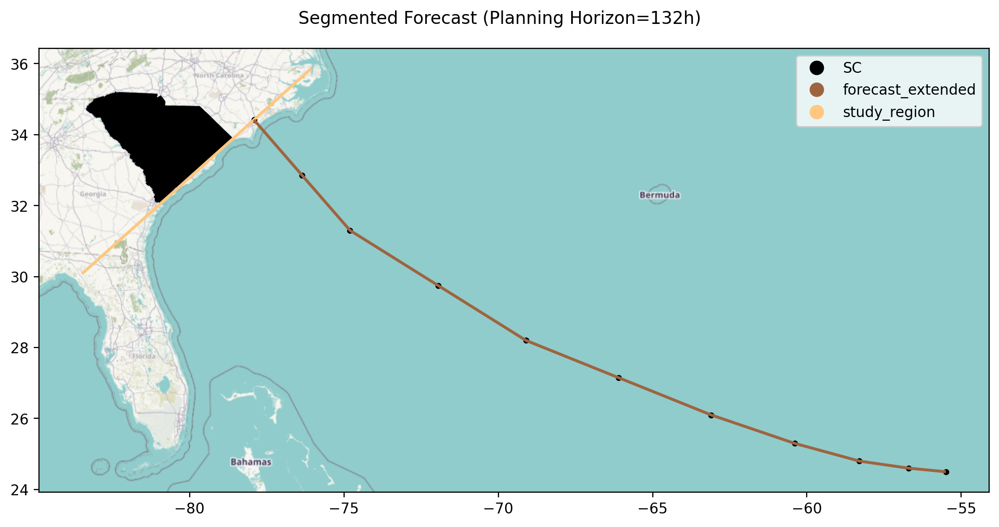

In [54]:
'''Plot the extended forecast track'''
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
geoms.plot(ax=ax)
pd.concat([geoms, forecast_ext_gdf]).plot(
    ax=ax, cmap='copper', linewidth=2, marker='x', column='object', legend=True
    )
gpd.GeoSeries(
    points_from_ls(forecast_ext_gdf.geometry),
    crs=forecast_ext_gdf.crs
    ).plot(ax=ax, color='black', marker='o', markersize=10)
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=6, attribution=False)
fig.suptitle(f'Segmented Forecast (Planning Horizon={T*12}h)')
plt.tight_layout()

## Axis at the points of segmentation of forecast horizon

In [55]:
'''create lines parallel to study region at all forecast points'''
max_err = abs(samples_track).max()
right_extremes = np.column_stack(
    track_pos_from_cross_err(forecast_ext, [max_err]*forecast_ext.shape[0])
)
left_extremes = np.column_stack(
    track_pos_from_cross_err(forecast_ext, [-max_err]*forecast_ext.shape[0])
)
lines_extremes = list(
    LineString(point) for point in zip(right_extremes, left_extremes)
)
cross_axis_extended_gdf = gpd.GeoDataFrame({
    'object': [f'axis_{t}' for t in range(forecast_ext.shape[0])],
    'geometry': lines_extremes
    }, crs=args['CRS'])

## Regions indicating the signs (+/-) of forecast errors

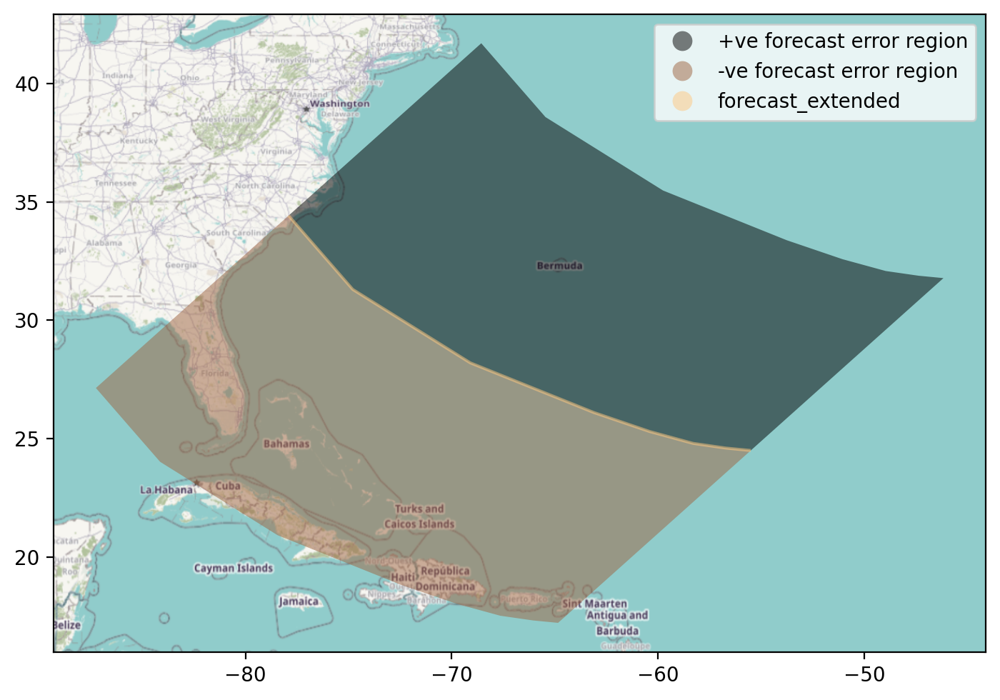

In [56]:
pos_error_region  = polygon_from_two_lines(
    forecast_ext_gdf.loc[0, 'geometry'],
    LineString(right_extremes)
    )
neg_error_region  = polygon_from_two_lines(
    forecast_ext_gdf.loc[0, 'geometry'],
    LineString(left_extremes)
    )

df_fore_sign = forecast_ext_gdf.copy()
df_fore_sign = pd.concat([
    df_fore_sign,
    gpd.GeoDataFrame({'object': ['+ve forecast error region'],
                      'geometry': [pos_error_region]}, crs=args['CRS']),
    gpd.GeoDataFrame({'object': ['-ve forecast error region'],
                      'geometry': [neg_error_region]}, crs=args['CRS'])
    ])

# Plot the error regions
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
df_fore_sign.plot(
    ax=ax, column='object', legend=True, alpha=0.5, cmap='copper'
    )
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)
plt.tight_layout()

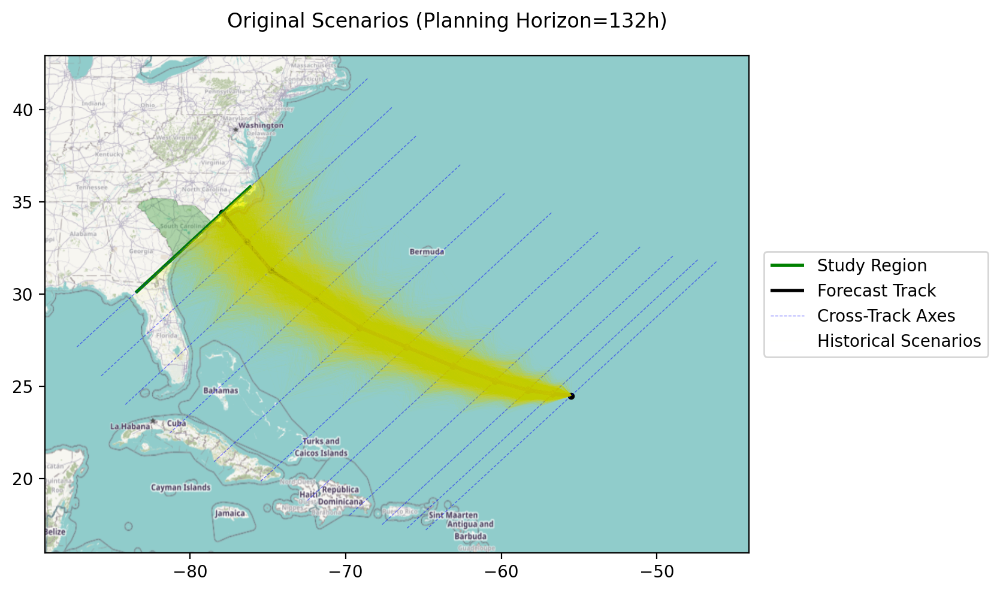

In [57]:
'''Plot the extended forecast track'''
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
geoms[geoms['object'] == 'study_region'].plot(
    ax=ax, color='green', linewidth=2, label='Study Region'
    )
geoms[geoms['object'] == 'SC'].plot(
    ax=ax, color='green', alpha=0.3,
    )
forecast_ext_gdf.plot(
    ax=ax, color='black', linewidth=2, marker='x',
    label='Forecast Track'
    )
gpd.GeoSeries(
    points_from_ls(forecast_ext_gdf.geometry),
    crs=forecast_ext_gdf.crs
    ).plot(ax=ax, color='black', marker='o', markersize=10)
cross_axis_extended_gdf.plot(
    ax=ax, color='blue', linestyle='--', linewidth=0.5, alpha=0.5,
    label='Cross-Track Axes'
    )
gdf_scen_truncated.plot(
    ax=ax, color='yellow', alpha=0.1, linewidth=0.05,
    label='Historical Scenarios'
    )
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)
ax.legend(bbox_to_anchor=(1.01, 0.5), loc='center left')
fig.suptitle(f'Original Scenarios (Planning Horizon={T*12}h)')
plt.tight_layout()

## Extended scenarios generation

In [58]:
# (num_scen, T*segments, (long, lat))
scen_extended = np.zeros((args['num_scen'], T_exteneded, 2))
for s in range(args['num_scen']):
    scen_line = gdf_scen_truncated.loc[s, 'geometry']
    for step in planning_horizon_extended:
        if step % args['segments'] == 0:
            scen_extended[s, step] = scen_truncated[s, step // args['segments']]
            continue
        cross_line = cross_axis_extended_gdf.loc[step, 'geometry']
        try:
            ix, iy = point_of_intersection(cross_line, scen_line)
        except AssertionError as e:
            print(f"No intersection for scenario {s}, step {step}")
            raise e
        scen_extended[s, step] = [ix, iy]

lines_extended = [LineString(scen_extended[i]) for i in range(scen_extended.shape[0])]
gdf_scen_extended = gpd.GeoDataFrame({'geometry': lines_extended}, crs=args['CRS'])

Text(0.5, 0.98, 'Segmented Scenarios (Planning Horizon=132h)')

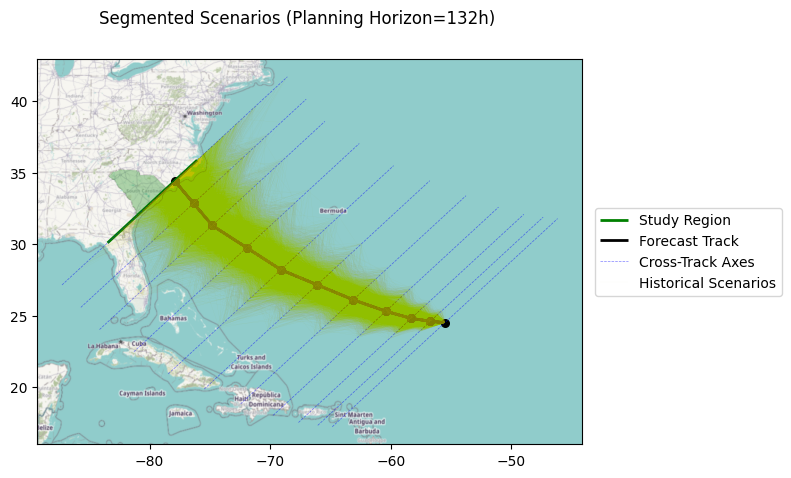

In [59]:
'''Plot the extended forecast track'''
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
geoms[geoms['object'] == 'study_region'].plot(
    ax=ax, color='green', linewidth=2, label='Study Region'
    )
geoms[geoms['object'] == 'SC'].plot(
    ax=ax, color='green', alpha=0.3,
    )
forecast_ext_gdf.plot(
    ax=ax, color='black', linewidth=2, marker='x',
    label='Forecast Track'
    )
gpd.GeoSeries(
    points_from_ls(forecast_ext_gdf.geometry),
    crs=forecast_ext_gdf.crs
    ).plot(ax=ax, color='black', marker='o', markersize=30)
cross_axis_extended_gdf.plot(
    ax=ax, color='blue', linestyle='--', linewidth=0.5, alpha=0.5,
    label='Cross-Track Axes'
    )
gdf_scen_extended.plot(
    ax=ax, color='y', alpha=0.1, linewidth=0.1,
    label='Historical Scenarios'
    )
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)
ax.legend(bbox_to_anchor=(1.01, 0.5), loc='center left')
fig.suptitle(f'Segmented Scenarios (Planning Horizon={T*12}h)')

## Forecast error from the segmented scenarios

In [60]:
fore_error_extended = np.zeros((args['num_scen'], T_exteneded))

for s in range(args['num_scen']):
    for t in range(T_exteneded):
        if t % args['segments'] == 0:
            fore_error_extended[s, t] = samples_track[s, t // args['segments']]
            continue
        lon_f, lat_f = forecast_ext.loc[t, ['Longitude', 'Latitude']]
        lon_s, lat_s = scen_extended[s, t]
        dx = (lon_s - lon_f) * args['LONG_TO_MILES']  # difference in miles
        dy = (lat_s - lat_f) * args['LAT_TO_MILES']  # difference in miles
        fore_error_magnitude = np.hypot(dx, dy)
        # Determine the sign of the forecast error based on its spatial orientation
        # (left/right) relative to the forecast track.
        if pos_error_region.covers(Point(lon_s, lat_s)):
            fore_error_sign = 1  # forecast error is +ve
        elif neg_error_region.covers(Point(lon_s, lat_s)):
            fore_error_sign = -1  # forecast error is -ve
        else:
            raise AssertionError(f"error in sign(+/-) determination")
        fore_error_extended[s, t] = fore_error_magnitude * fore_error_sign

print(
    'Descriptive statistics of segmented forecast error data '
    '(each row represents a time period):'
    )
pd.DataFrame(fore_error_extended).describe().transpose()

Descriptive statistics of segmented forecast error data (each row represents a time period):


,count,mean,std,min,25%,50%,75%,max
0,10000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,10000.0,-0.585073,18.582325,-74.250386,-11.000000,0.000000,10.000000,95.118827
2,10000.0,-1.714582,32.775690,-141.568994,-20.000000,0.000000,17.000000,126.122225
3,10000.0,-1.991280,46.109129,-181.426673,-26.000000,0.000000,23.000000,181.770498
4,10000.0,-2.895913,57.698060,-254.017328,-35.049068,1.000000,30.000000,229.525904
5,10000.0,-2.853473,67.236673,-319.517761,-35.992382,2.000000,33.000000,283.947349
6,10000.0,-4.413352,84.884469,-403.181051,-46.000000,0.000000,41.000000,372.850302
7,10000.0,0.895013,90.048197,-438.808418,-47.000000,2.000000,50.000000,403.457730
8,10000.0,2.117752,115.690886,-519.457183,-62.549628,3.000000,66.177515,484.565617
9,10000.0,6.785095,121.232147,-527.350432,-62.000000,5.000000,70.000000,556.505608


<Axes: >

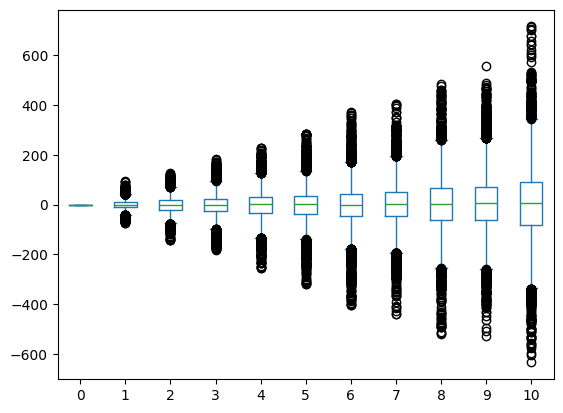

In [61]:
pd.DataFrame(fore_error_extended).plot.box()

# MC Discretization
- Once we obtain the forecast error data for the new segments, we apply MC discretization.
- Intensity can be discretized using SS-Scale (https://www.nhc.noaa.gov/aboutsshws.php)
- Track can be discretized using Stochastic Approximation (see section 4.3 Markov chain approximation (MCA) of https://optimization-online.org/wp-content/uploads/2019/05/7199.pdf)

## Intensity Discretization
- Add the forecast errors to the point forecast.
- Obtain the hurricane category
- Compute the transition probabilities

### Segmentation of intensity forecast errors

In [62]:
'''Create points in between subsequest forecast points at 12 hours lead time'''
# the starting point of fixed for track and intensity forecast
state_space_intensity = list(range(6))
fore_error_int_ext = [samples_intensity[:, 0].tolist()]
for t in range(1, T):
    int_start = fore_error_int_ext[-1]
    int_end = samples_intensity[:, t]
    int_inter_points = np.linspace(int_start, int_end, args['segments'] + 1)
    fore_error_int_ext += list(int_inter_points.tolist()[1:])
fore_error_int_ext = np.array(fore_error_int_ext).transpose()
fore_error_int_ext

array([[  0.        ,  -3.26369748, -18.72391172, ..., -17.22203395,
        -16.96353927, -18.45108527],
       [  0.        ,  -1.20723054,   8.17209806, ..., -13.49147187,
        -11.41308454, -12.59367592],
       [  0.        ,   1.2964588 ,   1.68586035, ...,   3.80851285,
          5.39564055, -18.44493714],
       ...,
       [  0.        ,   2.65640126,   5.37448378, ..., -13.4304249 ,
         -7.08233161,   4.66711965],
       [  0.        ,   2.05556726,  13.41152338, ...,  17.5269464 ,
         10.22617742,   9.99017604],
       [  0.        , -10.05897079, -11.83602218, ..., -11.39832102,
        -16.3628962 , -19.46901457]])

<Axes: >

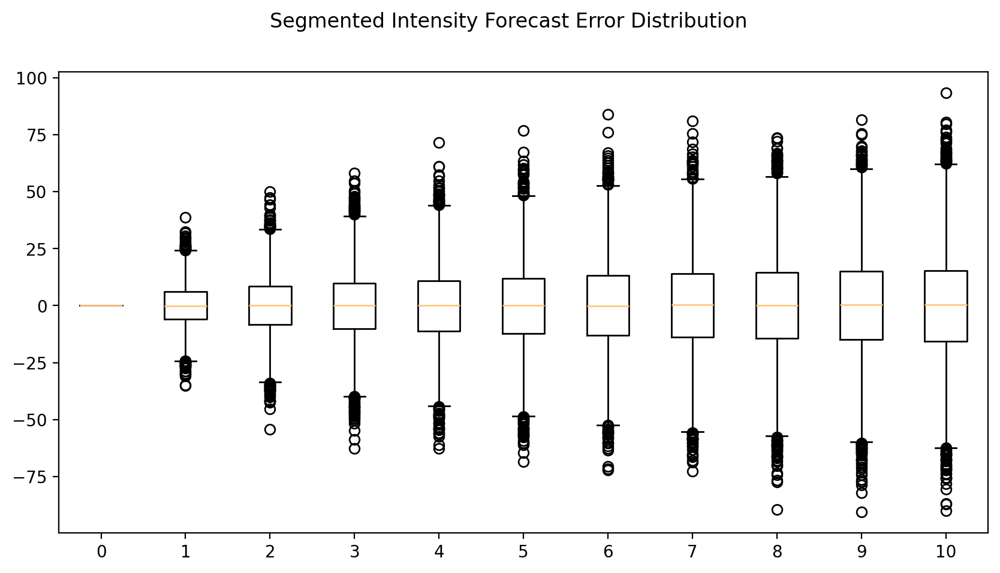

In [63]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
fig.suptitle('Segmented Intensity Forecast Error Distribution')
pd.DataFrame(fore_error_int_ext).plot(
    ax=ax, kind='box', legend=False, colormap='copper'
    )

### Create intentisy scenarios for the extended planning horizon

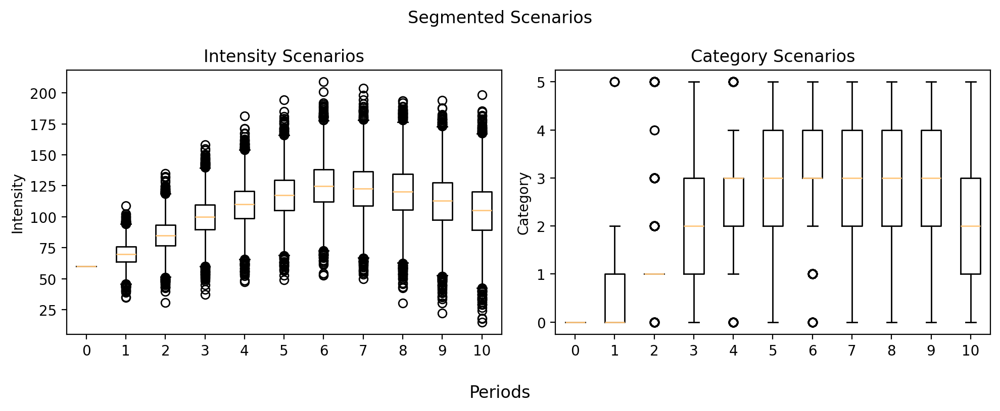

In [64]:
scen_ext_int = forecast_ext['Intensity'].values + fore_error_int_ext
cat_ext_int = np.vectorize(hurr_cat)(scen_ext_int)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=200)
pd.DataFrame(scen_ext_int).plot(ax=ax[0], kind='box', cmap='copper')
pd.DataFrame(cat_ext_int).plot(ax=ax[1], kind='box', cmap='copper')
ax[0].set_title('Intensity Scenarios'); ax[0].set_ylabel('Intensity')
ax[1].set_title('Category Scenarios'); ax[1].set_ylabel('Category')
fig.supxlabel('Periods'); fig.suptitle('Segmented Scenarios')
plt.tight_layout()

<Axes: >

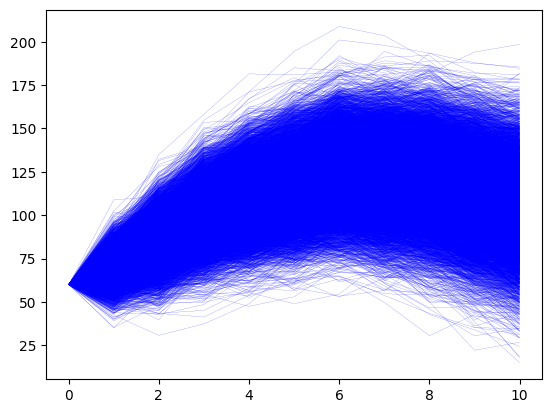

In [65]:
pd.DataFrame(scen_ext_int).transpose().plot(
    kind='line', legend=False, linewidth=0.1, color='b'
    )

### Compute transition counts and transition probabilities

In [66]:
def transition_counts(paths):
    """
    paths: array-like shape (n_paths, T) with discrete states (ints or hashable)
    """
    paths = np.asarray(paths)
    _, T = paths.shape
    states = np.asarray(np.unique(paths))
    n_states = len(states)
    transitions = np.zeros((T - 1, n_states, n_states), dtype=int)
    for t in range(T - 1):
        for s in range(args['num_scen']):
            last_state, next_state = paths[s, t], paths[s, t + 1]
            transitions[t, last_state, next_state] += 1
    return transitions

transitions = transition_counts(cat_ext_int)
transitions_time_homogeneous = np.sum(transitions, axis=0)

In [67]:
'''Estimate transition probability matrix from the empirical transitions'''
def compute_prob(array):
    assert array.ndim == 2, "Input array must be 2-dimensional"
    row_sums = array.sum(axis=1, keepdims=True)
    row_sums_safe = np.where(row_sums == 0, 1, row_sums)
    p = array / row_sums_safe
    zero_rows = (row_sums.squeeze(-1) == 0)
    p[zero_rows, :] = 0.0
    return p.round(3)

prob_matrix = np.array(
    [compute_prob(transitions[t]) for t in range(transitions.shape[0])]
    )
prob_matrix_intensity_time_homogeneous = compute_prob(transitions_time_homogeneous)

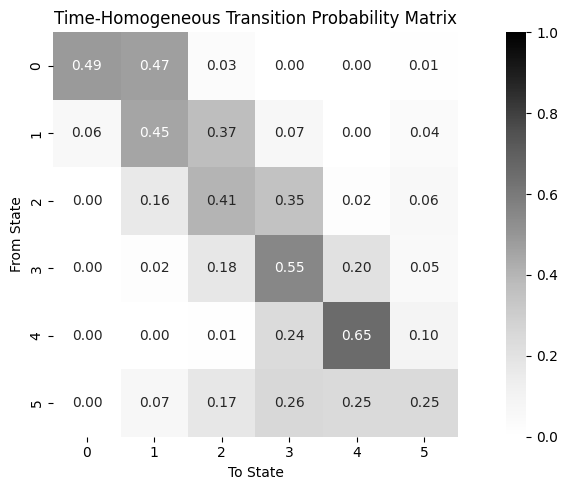

In [68]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
sns.heatmap(
    prob_matrix_intensity_time_homogeneous, annot=True, fmt=".2f", ax=ax,
    vmin=0, vmax=1, cmap='Greys', square=True
    )
ax.set_title('Time-Homogeneous Transition Probability Matrix')
ax.set_xlabel('To State')
ax.set_ylabel('From State')
plt.tight_layout()

### Export

In [69]:
def array_to_nested_dict(arr):
    arr = np.asarray(arr)
    def convert(a):
        if a.ndim == 0:
            return a.item() if isinstance(a, np.generic) else a
        return {i: convert(a[i]) for i in range(a.shape[0])}
    return convert(arr)

export_intensity_data = {
    'time_heterogeneous': array_to_nested_dict(prob_matrix),
    'time_homogeneous': array_to_nested_dict(prob_matrix_intensity_time_homogeneous)
}

file_name = 'Florence_intensity_mc_p_matrix_{}_{}.json'.format(
    args['H'],
    args['segments'],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
with open(out_path, 'w') as export_file:
    json.dump(export_intensity_data, export_file, indent=4)

## Track discretization via stochastic approximation

In [70]:
def discretize(xi: np.array, num_states: int):
    """
    Discretize a 1D sample vector into num_states representative states
    using a stochastic approximation (SA) update. xi is a 1D array of
    sample realizations of track forecast error.
    """
    xi = np.asarray(xi)
    num_training_samples = len(xi)
    # 1. Initialize state means using quantiles
    quantiles = np.linspace(0, 100, num_states + 2)[1:-1]
    mu = np.percentile(xi, quantiles)
    # 2. Online update of closest mean (stochastic k-means)
    for s in range(num_training_samples):
        beta = 1.0 / (s + 1)  # diminishing step size
        k = np.argmin((xi[s] - mu) ** 2)
        mu[k] = (1 - beta) * mu[k] + beta * xi[s]
    mu = np.round(mu, 2)
    # 3. Assign samples to nearest state
    distances = np.abs(xi[:, None] - mu[None, :])
    assign = np.argmin(distances, axis=1)
    gamma = {m: [] for m in mu}
    for s, k in enumerate(assign):
        gamma[mu[k]].append(s)
    # 4. Compute average discretization loss
    avg_loss = np.mean(np.abs(xi - mu[assign]))

    return mu, avg_loss, assign, gamma

In [71]:
state_space_track = {}
assignments = {}
gammas = {}
losses = {}
avg_loss_terminal = 1e5  # large initial value

for t in reversed(range(T_exteneded)):
    N = args['n_states_at_terminal']
    xi = fore_error_extended[:, t]
    while True:
        mu, avg_loss, assign, gamma = discretize(xi, N)
        if t == T_exteneded - 1:
            avg_loss_terminal = avg_loss
            status = 1
        else:
            if avg_loss >= avg_loss_terminal or N == 1:
                status = 1
            else:
                status = 0
                N -= 1
        if status == 1:
            state_space_track[t] = mu
            assignments[t] = np.array(assign)
            losses[t] = avg_loss
            gammas[t] = gamma
            break
        else:
            continue

In [72]:
'''
The state space of the discretized MC model for the track forecast error
'''
print('The track forecast error state space (t: states) is')
for t, states in state_space_track.items():
    print(f'{t}: {states}')

The track forecast error state space (t: states) is
10: [-179.14  -54.42   17.67   96.84  251.92]
9: [-120.49   12.51  143.73]
8: [-148.52  -24.7    71.56  247.96]
7: [-72.44  61.24]
6: [-56.9   68.79]
5: [-2.85]
4: [-2.9]
3: [-1.99]
2: [-1.71]
1: [-0.59]
0: [0.]


### Transition counts & probabilities between discretized states

In [73]:
'''
The transition counts are computed based on the intersection of gamma sets.
The transition probability matrices are then derived from the counts.
'''
transition_matrices_track = {}
transition_probabilities_track = {}

for t in range(T_exteneded - 1):
    transition_matrix_t = {}
    states_t = state_space_track[t]
    states_tp1 = state_space_track[t + 1]
    for last_state in states_t:
        gamma_last_state = gammas[t][last_state]
        transition_matrix_t[last_state] = {
            next_state: len(list(
                set(gamma_next_state) & set(gamma_last_state)
                ))
            for next_state, gamma_next_state in gammas[t + 1].items()
        }
    transition_matrices_track[t] = pd.DataFrame(transition_matrix_t).T
    transition_probabilities_track[t] = transition_matrices_track[t].div(
        transition_matrices_track[t].sum(axis=1), axis=0
        ).fillna(0).round(3)

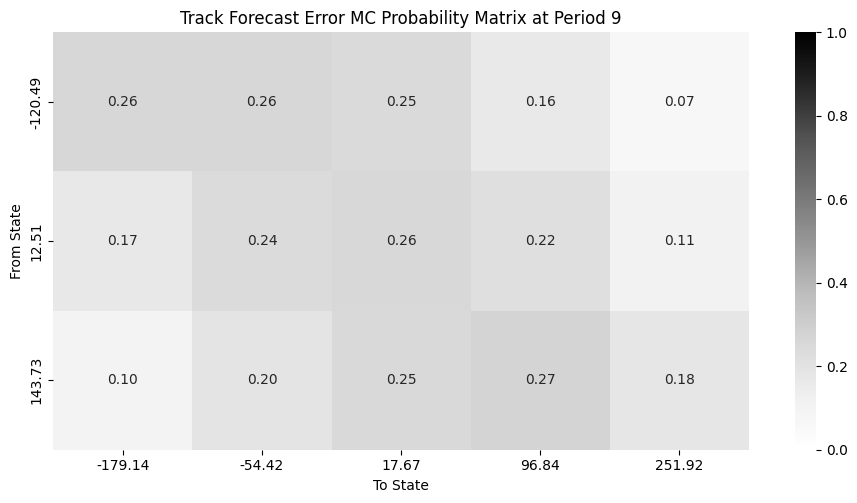

In [74]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
sns.heatmap(
    transition_probabilities_track[t], annot=True, fmt=".2f", ax=ax,
    vmin=0, vmax=1, cmap='Greys', square=True
    )
ax.set_title(f'Track Forecast Error MC Probability Matrix at Period {t}')
ax.set_xlabel('To State')
ax.set_ylabel('From State')
plt.tight_layout()

### Export

In [75]:
track_transition_prob_dict = {}
for period,dataframe in transition_probabilities_track.items():
    track_transition_prob_dict[period] = dataframe.to_dict(orient='index')
file_name = 'Florence_track_mc_p_matrix_{}_{}_{}.json'.format(
    args['H'],
    args['segments'],
    args['n_states_at_terminal'],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
with open(out_path, 'w') as export_file:
    json.dump(track_transition_prob_dict, export_file, indent=4)

## Combined MC Model (Intensity & Track)
- Since track and intensity are independent of each other, we can take the cartisean product of the individual state spaces to get the combined state space.

In [76]:
combined_state_space = {}
for t in range(T_exteneded):
    if t == 0:
        track_state0 = state_space_track[t][0]
        intensity_state0 = hurr_cat(intensity_fore_extended[0])
        combined_state_space[t] = [(track_state0, intensity_state0)]
        continue
    track_states = state_space_track[t]
    intensity_state = state_space_intensity
    combined_state_space[t] = list(
        itertools.product(track_states, intensity_state)
        )

In [77]:
combined_mc_transition_prob = {}
for t, state_space_t in combined_state_space.items():
    if t < T_exteneded - 1:
        combined_mc_transition_prob[t] = {}
        for state in state_space_t:
            state_track, state_int = state
            combined_mc_transition_prob[t][state] = {
                state_tp1:
                track_transition_prob_dict[t][state_track][state_tp1[0]] *
                prob_matrix_intensity_time_homogeneous[state_int][state_tp1[1]]
                for state_tp1 in combined_state_space[t + 1]
            }

In [78]:
# convert combined_mc_transition_prob keys to "(..., ...)" strings (tuples)
combined_mc_transition_prob_strkeys = {}
for t, trans in combined_mc_transition_prob.items(): # loop over time steps
    combined_mc_transition_prob_strkeys[t] = {} # create a dict for each time step
    for state, nxt in trans.items(): # loop over each current state at time t    # nxt is the dict of transitions from that state to all next states at t+1 
        state_key = str((float(state[0]), int(state[1]))) # Convert state tuple to a standardized "(track, intensity)" string key
        combined_mc_transition_prob_strkeys[t][state_key] = {str((float(st_tp1[0]), int(st_tp1[1]))): prob for st_tp1, prob in nxt.items()}


### Export

In [79]:
file_name = 'Florence_combined_mc_p_matrix_{}_{}_{}.json'.format(
    args['H'],
    args['segments'],
    args['n_states_at_terminal'],
)

def make_json_safe(obj):
    if isinstance(obj, dict):
        out = {}
        for k, v in obj.items():
            if isinstance(k, tuple):
                k2 = json.dumps(
                    [x.item() if isinstance(x, np.generic) else x for x in k]
                    )
            elif isinstance(k, np.generic):
                k2 = str(k.item())
            else:
                k2 = str(k)
            out[k2] = make_json_safe(v)
        return out
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(x) for x in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    return obj

safe_combined = make_json_safe(combined_mc_transition_prob_strkeys)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
with open(out_path, 'w') as export_file:
    json.dump(safe_combined, export_file, indent=4)

# Demand Mapping

- Estimate demand at a predefined set of demand points using the point forecast and associated forecast errors (track and intensity).

- Track error and point forecast locations are provided directly as inputs.  
  Intensity, however, is represented through categorical classes derived by combining forecast errors with the static forecast.

- These intensity categories, rather than raw intensity values, are used as inputs to the demand mapping process.

- The parameter *demand_lead_time* from `data/inputs.json` determines the first time period in which demand is observed.  
  For example, if *demand_lead_time* = 48 hours, then demand is first observed 48 hours before landfall; prior to this point, demand is assumed to be zero.

- This threshold is used to determine:
  1. The first time period in which demand is observed.
  2. The time-dependent demand profile, assuming a fixed forward speed:
     - The parameter *x_max* for track-based demand is computed from the hurricane’s position *demand_lead_time* hours before landfall.
     - Time-based demand (with respect to forward movement) is computed using the distance of the hurricane from the study region.


## Initial parameters and data

In [80]:
tau_12h = int(args['demand_lead_time'] / 12) + 1
tau = len(range((tau_12h - 1) * args['segments'] + 1))
study_line = geoms.loc[geoms['object']=='study_region', 'geometry'].values[0] # Extract the geometry (line) representing the study region (e.g., coastline)
study_region_dist = args['study_region_dist']                                 # Maximum lateral distance from study region that can generate demand (miles)
'''along-distance from the starting point of evacuation to the study region'''
forecast_loc_tau = forecast_ext.loc[                                          # Get the hurricane’s location at the time demand starts
    T_exteneded - tau, ['Longitude', 'Latitude']
    ].values
study_line_extended = extend_straight_line(study_line, 10**3)                 # Extend the study-region line so projections always work (avoid edge issues)
interpolated_dist = study_line_extended.project(                              # Project the hurricane point onto the study line
    Point(forecast_loc_tau), normalized=True
    )

# ---- save study_line_extended-----------------------------------------------------
file_name = "study_line_extended_{}_{}_{}.geojson".format(
    args["H"],
    args["segments"],
    args["n_states_at_terminal"],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)

gpd.GeoSeries([study_line_extended], crs=args["CRS"]).to_file(out_path, driver="GeoJSON")
# ----------------------------------------------------------------------------------

nearest_pt = study_line_extended.interpolate(interpolated_dist, normalized=True) # Convert that relative position into the closest point on the study line
x_max = np.sqrt(                                                                 # Compute distance (in miles) from hurricane to study region at demand start
    ((forecast_loc_tau[0] - nearest_pt.x) * args['LONG_TO_MILES']) ** 2 +
    ((forecast_loc_tau[1] - nearest_pt.y) * args['LAT_TO_MILES']) ** 2
)


# -------------------- save x_max --------------------
file_name = "x_max_{}_{}_{}.json".format(
    args["H"],
    args["segments"],
    args["n_states_at_terminal"],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
with open(out_path, "w") as f:
    json.dump({"x_max": float(x_max)}, f, indent=2)
# -----------------------------------------------------

## Demand Zone
- Area in which the demand is non-zero.

In [81]:
study_region_south = study_line.coords[0]
study_region_north = study_line.coords[-1]
demand_zone_v1 = [study_region_south[0] + (x_max * y_rotate)/args['LONG_TO_MILES'],
                  study_region_south[1] - (x_max * x_rotate)/args['LAT_TO_MILES']]
demand_zone_v2 = [study_region_north[0] + x_max * y_rotate/args['LONG_TO_MILES'],
                  study_region_north[1] - x_max * x_rotate/args['LAT_TO_MILES']]
demand_zone = Polygon(
    [demand_zone_v1, demand_zone_v2, study_region_north, study_region_south]
    )

# -------------------- save demand_zone -------------------------------------------------------------
file_name = "demand_zone_{}_{}_{}.geojson".format(
    args["H"],
    args["segments"],
    args["n_states_at_terminal"],
)
instance_dir = os.path.join("mc_output", f"mc_{args['H']}_{args['segments']}_{args['n_states_at_terminal']}")
os.makedirs(instance_dir, exist_ok=True)
out_path = os.path.join(instance_dir, file_name)
gpd.GeoSeries([demand_zone], crs=args["CRS"]).to_file(out_path, driver="GeoJSON")
# --------------------------------------------------------------------------------------------------

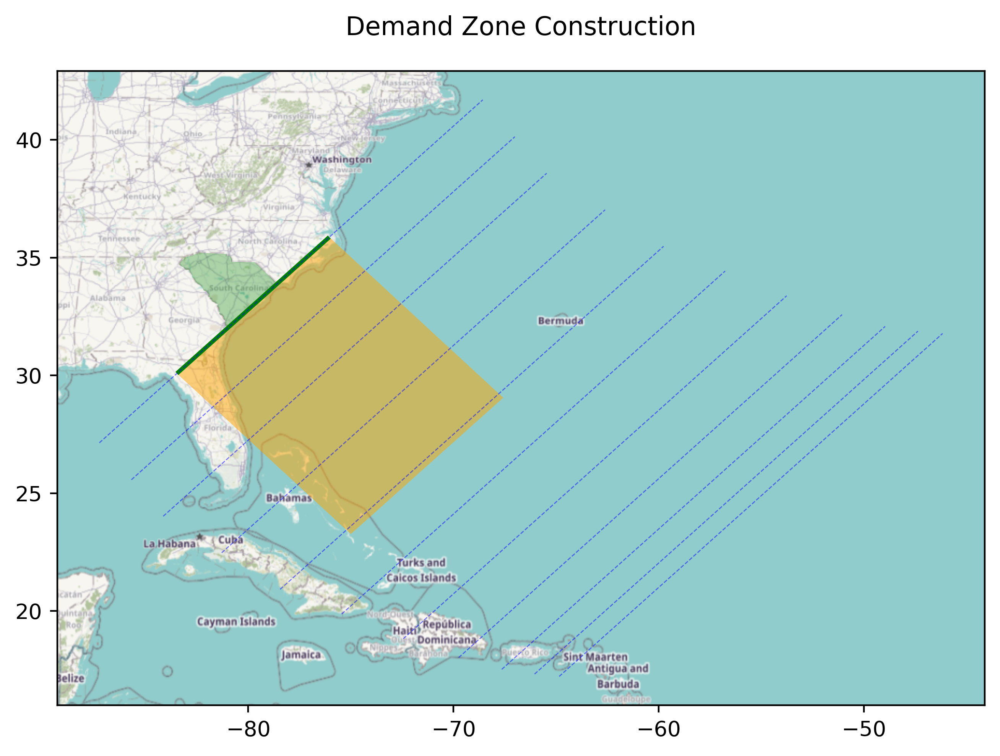

In [82]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=400)
geoms[geoms['object'] == 'study_region'].plot(
    ax=ax, color='green', linewidth=2, label='Study Region'
    )
geoms[geoms['object'] == 'SC'].plot(
    ax=ax, color='green', alpha=0.3,
    )
cross_axis_extended_gdf.plot(
    ax=ax, color='blue', linestyle='--', linewidth=0.5, alpha=0.5,
    label='Cross-Track Axes'
    )
gpd.GeoSeries(
    demand_zone, crs=geoms.crs
    ).plot(ax=ax, color='orange', alpha=0.5, label='Demand Zone')
ctx.add_basemap(ax, crs=geoms.crs.to_string(), zoom=5, attribution=False)
fig.suptitle('Demand Zone Construction')
plt.tight_layout()

## Demand Computation Function

In [ ]:
'''Hurricane category to demand fraction mapping'''
def demand_by_hurr_cat(hurr_cat: int):
    assert 0 <= hurr_cat <= 5, "hurricane category should be in between 0 to 5"
    cat_lst = list(range(6))
    demand_frac_lst = np.linspace(0, 1, 6)
    for cat in cat_lst:
        if hurr_cat <= cat:
            return float(demand_frac_lst[cat])

In [ ]:

def demand_generation(dp_loc_array, track_error, hurr_cat, t):
    dp_loc_array = np.array(dp_loc_array)
    assert dp_loc_array.shape[1] == 2, "dp_loc_array must have shape (I, 2)"
    I = dp_loc_array.shape[0]
    demand = np.zeros(I)
    # from track-error and forecast, get the coordinates of the track point
    x = (
        forecast_ext.loc[t, 'Longitude'] +
        x_rotate * track_error / args['LONG_TO_MILES']
        )
    y = (
        forecast_ext.loc[t, 'Latitude'] +
        y_rotate * track_error / args['LAT_TO_MILES']
        )
    proj_point = study_line_extended.interpolate(
        study_line_extended.project(Point([x, y]))
        )
    # demand is zero if the track error is outside the study region
    # or if the lead-time greater than demand_lead_time (first-demand time)
    if (
        (not demand_zone.contains(Point([x, y]))) or
        (t < T_exteneded - tau)
        ):
        return demand
    # 1. demand by intensity
    demand_by_cat = demand_by_hurr_cat(hurr_cat)
    # 2. demand by time (W.R.T. the forward speed towards study region)
    diff_x = np.sqrt(
        ((proj_point.x - x) * args['LONG_TO_MILES']) ** 2 +
        ((proj_point.y - y) * args['LAT_TO_MILES']) ** 2
        )
    demand_by_time = max(1e-9, 1 - diff_x / x_max)
    # 3. demand by track error (W.R.T lateral distance along the study region)
    diff_y = np.zeros(I)
    for i in range(I):
        diff_y = np.sqrt(
            ((proj_point.x - dp_loc_array[i, 0]) * args['LONG_TO_MILES'])**2 +
            ((proj_point.y - dp_loc_array[i, 1]) * args['LAT_TO_MILES'])**2
            )
        demand_by_track = max(1e-9, 1 - diff_y / study_region_dist)
        # combined demand
        demand[i] = demand_by_track * demand_by_time * demand_by_cat
    return demand

### Stress Testing the Demand Mapping Function

In [ ]:
n_tests = 1000
results = []
for i in range(n_tests):
    test_args = {
        'dp_loc_array': [[-80.66, 32.27],
                         [-79.72, 33.00],
                         [-78.85, 33.69],
                         [-80.07, 32.74],
                         [-79.30, 33.33]
                        ],
        'track_error': np.random.normal(0, 100),          
        'hurr_cat': np.random.choice([0, 1, 2, 3, 4, 5]),
        't': np.random.randint(T_exteneded - tau, T_exteneded)            
    }

    demand_vector = demand_generation(**test_args)
    
    # Store results along with args for debugging
    results.append({'args': test_args, 'demand': demand_vector})

    # Print only if negative values are present
    if np.any(demand_vector < 0):
        print('Negative demand detected!')
        print('Args:', test_args)
        print('Demand:', demand_vector)
print(
    'All tests completed. Number of cases with negative demand:',
    sum(np.any(r['demand'] < 0) for r in results)
    )
